# Measured canine gait — temporal continuity for upper-arm vs forearm IMUs

This is the same eight-code-cell notebook as the previous comparison, with **a simple gait-phase continuity penalty** added in code block 5. The diagnostic graphs in block 6 now compare the previous independent-frame estimate with the new continuity-constrained estimate; block 7 animates the new estimates.

Each candidate phase is scored by (1) how well the reference angle and angular velocity match the current measurement, and (2) how close the candidate is to the **next expected phase** given the phase estimate from the previous frame. The expected advance per frame is estimated from the *other/reference stride*, not from the tested stride. The first phase in each held-out stride is still estimated solely from the sensor measurement. The stride boundary resets are for this limited cross-stride validation exercise; a deployed controller would need continuous tracking or event-based resets.

The CSV contains one measured forelimb (left) only. Right-leg targets are an illustrative half-cycle-shifted empirical reference, not independent right-leg observations. The data span just two complete strides, and the labels are assigned from toe extrema rather than verified foot contacts. Video-derived segment angles approximate IMU output but are not true inertial sensor recordings. No real video sampling rate or physical length scale was provided, so angular rates are per frame and lengths are forearm-normalized.

Place `dog_positions(Sheet1) (1).csv` in this notebook's working directory. Requires a functional LaTeX installation for `plt.rc('text', usetex=True)`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML

plt.rc("font", family="serif", size=10)
plt.rc('text', usetex=True)

# Read and lightly smooth the four tracked landmarks.
df = pd.read_csv("dog_positions.csv")
df.columns = df.columns.str.strip()
frames = df["Frame"].to_numpy()
for color in ["Blue", "Red", "Yellow", "Green"]:
    for axis in "XY":
        col = color + axis
        df[col] = df[col].rolling(3, center=True, min_periods=1).median()
        df[col] = df[col].rolling(3, center=True, min_periods=1).mean()

# Shoulder-relative coordinates, with image y inverted to point upward.
points = {}
for color in ["Red", "Yellow", "Green"]:
    points[color] = np.column_stack((
        df[color + "X"] - df["BlueX"],
        df["BlueY"] - df[color + "Y"]
    ))

# Approximate camera rotation (in degrees); set 0 if correction is unwanted.
tilt = np.deg2rad(1.0)
rotation = np.array([[np.cos(tilt), -np.sin(tilt)],
                     [np.sin(tilt),  np.cos(tilt)]])
points = {name: xy @ rotation.T for name, xy in points.items()}

# Normalize by the median measured forearm length: L2 = 1 unit.
scale = np.median(np.linalg.norm(points["Yellow"] - points["Red"], axis=1))
elbow = points["Red"] / scale
wrist = points["Yellow"] / scale
toe = points["Green"] / scale
L1 = np.median(np.linalg.norm(elbow, axis=1))
L2 = 1.0
L3 = np.median(np.linalg.norm(toe - wrist, axis=1))

# Two complete cycles, chosen from the toe's forward-most positions.
cycle_bounds = [(11, 29), (29, 50)]
frame_ids = np.arange(11, 50)  # includes two cycles; excludes partial ends
n_frames = len(frame_ids)
s_left_true = np.interp(frame_ids, [11, 29, 50], [0, 1, 2]) % 1
phase_grid = np.linspace(0, 1, 120, endpoint=False)
fps = 20  # GIF display rate only; the CSV does not specify video fps.

print(f"Normalized link lengths: {L1:.3f}, {L2:.3f}, {L3:.3f}")

Normalized link lengths: 0.858, 1.000, 0.539


In [2]:
def inverse_kinematics_3link(x, y, phi, L1, L2, L3, elbow_sign=1):
    """Desired toe position and paw angle -> three joint angles."""
    xw = np.asarray(x) - L3 * np.cos(phi)
    yw = np.asarray(y) - L3 * np.sin(phi)
    c2 = (xw**2 + yw**2 - L1**2 - L2**2) / (2*L1*L2)
    if np.any(np.abs(c2) > 1 + 1e-9):
        raise ValueError("Unreachable wrist target")
    c2 = np.clip(c2, -1, 1)
    s2 = elbow_sign * np.sqrt(1 - c2**2)
    theta2 = np.arctan2(s2, c2)
    theta1 = np.arctan2(yw, xw) - np.arctan2(L2*s2, L1 + L2*c2)
    theta3 = phi - theta1 - theta2
    return theta1, theta2, theta3


def forward_kinematics_3link(theta1, theta2, theta3, L1, L2, L3):
    """Three angles -> shoulder, elbow, wrist, and toe positions."""
    sx, sy = 0.0, 0.0
    ex, ey = L1*np.cos(theta1), L1*np.sin(theta1)
    wx = ex + L2*np.cos(theta1 + theta2)
    wy = ey + L2*np.sin(theta1 + theta2)
    px = wx + L3*np.cos(theta1 + theta2 + theta3)
    py = wy + L3*np.sin(theta1 + theta2 + theta3)
    return sx, sy, ex, ey, wx, wy, px, py

In [3]:
# Build one average, periodic reference trajectory from the two measured cycles.
def cycle_average(values):
    return np.mean([
        np.interp(start + (end-start)*phase_grid, frames, values)
        for start, end in cycle_bounds
    ], axis=0)

# Paw orientation comes directly from the wrist-to-toe marker displacement.
paw_angle = np.unwrap(np.arctan2((toe-wrist)[:, 1], (toe-wrist)[:, 0]))
x_ref = cycle_average(toe[:, 0])
y_ref = cycle_average(toe[:, 1])
phi_ref = cycle_average(paw_angle)


def gait_trajectory(s):
    """Measured, averaged toe trajectory: phase -> (x, y, phi)."""
    s = np.asarray(s) % 1
    def periodic_interp(values):
        return np.interp(s, np.r_[phase_grid, 1.0], np.r_[values, values[0]])
    return periodic_interp(x_ref), periodic_interp(y_ref), periodic_interp(phi_ref)

In [4]:
# Recover orientation and angular velocity from the video: virtual IMU signals.
# Angular velocity is radians per *video frame*, since real fps is unknown.
upper_angle = np.unwrap(np.arctan2(elbow[:, 1], elbow[:, 0]))
fore_angle = np.unwrap(np.arctan2((wrist-elbow)[:, 1], (wrist-elbow)[:, 0]))
upper_omega = np.gradient(upper_angle, frames)
fore_omega = np.gradient(fore_angle, frames)

# Use the same tracked left leg for both candidate IMU placements.
# There are no measured right-leg landmarks in this CSV.

In [5]:
# Compare independent-frame phase lookup with a simple continuity constraint.
def estimate_phase(angle, omega, continuity_strength=0.0):
    estimated = np.zeros(n_frames)

    for i, (start, end) in enumerate(cycle_bounds):
        # Train the reference on the other stride.
        train_start, train_end = cycle_bounds[1 - i]
        stride_frames = train_end - train_start
        ref_frames = train_start + stride_frames * phase_grid
        a_ref = np.interp(ref_frames, frames, angle)
        w_ref = np.interp(ref_frames, frames, omega)
        test_idx = np.where((frame_ids >= start) & (frame_ids < end))[0]

        for j in test_idx:
            frame = frame_ids[j]
            score = ((angle[frame] - a_ref) / max(np.std(a_ref), 0.1))**2
            score += ((omega[frame] - w_ref) / max(np.std(w_ref), 0.01))**2

            if continuity_strength and j != test_idx[0]:
                # The phase should advance roughly one stride-frame per frame.
                step = 1 / stride_frames
                expected = (estimated[j-1] + step) % 1
                # Circular distance handles the wrap from 1 back to 0.
                difference = (phase_grid - expected + 0.5) % 1 - 0.5
                score += continuity_strength * (difference / step)**2

            estimated[j] = phase_grid[np.argmin(score)]

    return estimated


# Same penalty for both sensors; zero reproduces the original estimator.
continuity_strength = 0.02
s_upper_raw = estimate_phase(upper_angle, upper_omega)
s_fore_raw = estimate_phase(fore_angle, fore_omega)
s_upper = estimate_phase(upper_angle, upper_omega, continuity_strength)
s_fore = estimate_phase(fore_angle, fore_omega, continuity_strength)


def phase_rmse(estimated):
    error = (estimated - s_left_true + 0.5) % 1 - 0.5
    return np.sqrt(np.mean(error**2))


def large_phase_jumps(estimated):
    # Count only jumps within each test stride (not between validation folds).
    count = 0
    for start, end in cycle_bounds:
        values = estimated[(frame_ids >= start) & (frame_ids < end)]
        changes = (np.diff(values) + 0.5) % 1 - 0.5
        count += np.count_nonzero(np.abs(changes) > 0.15)
    return count


for label, raw, smooth in [
    ('Upper arm', s_upper_raw, s_upper),
    ('Forearm', s_fore_raw, s_fore),
]:
    print(f'{label}: RMSE {phase_rmse(raw):.3f} -> {phase_rmse(smooth):.3f} cycles; '
          f'large jumps {large_phase_jumps(raw)} -> {large_phase_jumps(smooth)}')

# The right leg is NOT measured: its reference is shifted half a cycle.
s_right_true = (s_left_true + 0.5) % 1
s_right_upper = (s_upper + 0.5) % 1
s_right_fore = (s_fore + 0.5) % 1


def get_angles(s):
    return inverse_kinematics_3link(*gait_trajectory(s), L1, L2, L3)


right_true = get_angles(s_right_true)
right_upper = get_angles(s_right_upper)
right_fore = get_angles(s_right_fore)

for angles, phase in [(right_true, s_right_true), (right_upper, s_right_upper),
                      (right_fore, s_right_fore)]:
    _, _, _, _, _, _, px, py = forward_kinematics_3link(*angles, L1, L2, L3)
    tx, ty, _ = gait_trajectory(phase)
    assert np.allclose(px, tx) and np.allclose(py, ty)
print('IK/FK checks passed.')

Upper arm: RMSE 0.146 -> 0.066 cycles; large jumps 5 -> 1
Forearm: RMSE 0.043 -> 0.040 cycles; large jumps 1 -> 0
IK/FK checks passed.


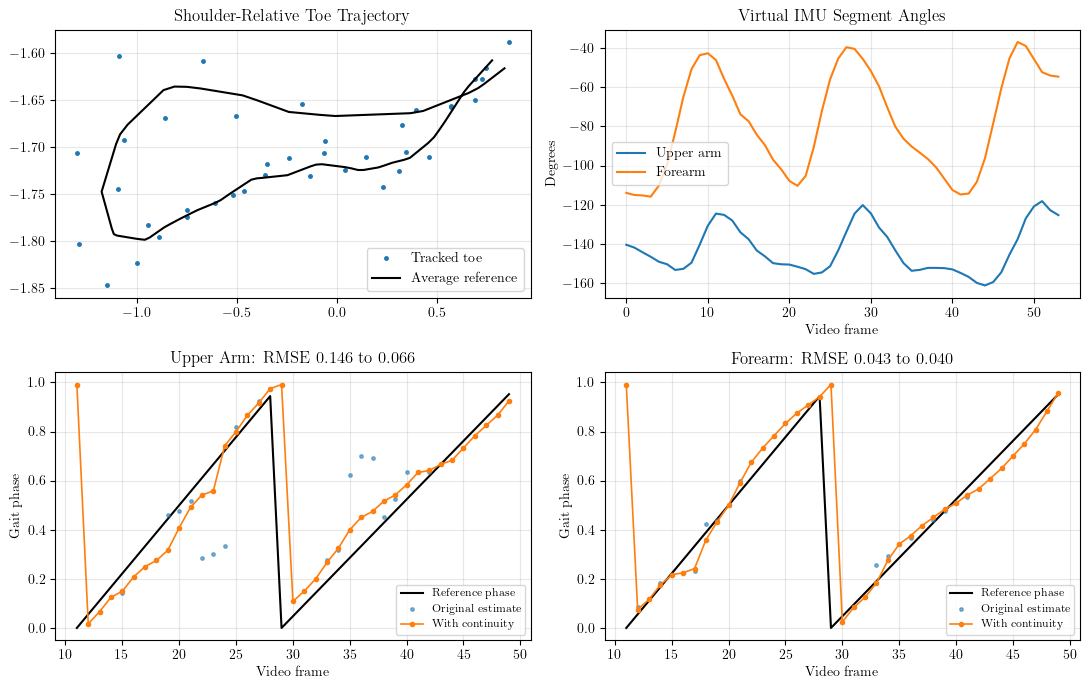

In [9]:
# Updated diagnostics: the original and continuity-constrained estimators.
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

axes[0, 0].plot(toe[frame_ids, 0], toe[frame_ids, 1], '.', ms=5,
                label='Tracked toe')
axes[0, 0].plot(x_ref, y_ref, color='black', label='Average reference')
axes[0, 0].set_title('Shoulder-Relative Toe Trajectory')
axes[0, 0].set_aspect('auto')
axes[0, 0].legend()

axes[0, 1].plot(frames, np.rad2deg(upper_angle), label='Upper arm')
axes[0, 1].plot(frames, np.rad2deg(fore_angle), label='Forearm')
axes[0, 1].set(title='Virtual IMU Segment Angles',
               xlabel='Video frame', ylabel='Degrees')
axes[0, 1].legend()

for ax, name, raw, smooth in [
    (axes[1, 0], 'Upper Arm', s_upper_raw, s_upper),
    (axes[1, 1], 'Forearm', s_fore_raw, s_fore),
]:
    ax.plot(frame_ids, s_left_true, color='black', label='Reference phase')
    ax.plot(frame_ids, raw, '.', ms=5, alpha=0.55,
            label='Original estimate')
    ax.plot(frame_ids, smooth, 'o-', ms=3, lw=1.2,
            label='With continuity')
    ax.set(title=f'{name}: RMSE {phase_rmse(raw):.3f} to {phase_rmse(smooth):.3f}',
           xlabel='Video frame', ylabel='Gait phase')
    ax.legend(fontsize=8)

for ax in axes.flat:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('gait_imu_temporal_diagnostics.png', dpi=150)
plt.show()

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.3), sharex=True, sharey=True)
reach = L1 + L2 + L3
floor = np.percentile(toe[frame_ids, 1], 10)  # illustrative ground guide

artists = []
for ax, title in zip(axes, ["Upper-arm virtual IMU", "Forearm virtual IMU"]):
    ax.set(xlim=(-1.75, 1.25), ylim=(-2.15, 0.15), title=title)
    ax.set_aspect("equal")
    ax.grid(alpha=0.25)
    ax.axhline(floor, ls="--", color="gray", alpha=0.6)
    left_line, = ax.plot([], [], "o-", color="red", lw=2.5, ms=5,
                         label="Left: measured")
    right_line, = ax.plot([], [], "o-", color="blue", lw=2.5, ms=5,
                          label="Right: predicted")
    reference_line, = ax.plot([], [], "--", color="black", lw=1.2,
                              alpha=0.6, label="Right: shifted reference")
    ax.legend(loc="lower right", fontsize=8)
    artists.append((left_line, right_line, reference_line))

def leg_points(angles, frame):
    sx, sy, ex, ey, wx, wy, px, py = forward_kinematics_3link(
        angles[0][frame], angles[1][frame], angles[2][frame], L1, L2, L3)
    return [sx, ex, wx, px], [sy, ey, wy, py]

def update(i):
    source = frame_ids[i]
    measured = ([0, elbow[source, 0], wrist[source, 0], toe[source, 0]],
                [0, elbow[source, 1], wrist[source, 1], toe[source, 1]])
    output = []
    for angles, (left_line, right_line, ref_line) in zip(
        [right_upper, right_fore], artists):
        left_line.set_data(*measured)
        right_line.set_data(*leg_points(angles, i))
        ref_line.set_data(*leg_points(right_true, i))
        output += [left_line, right_line, ref_line]
    return output

plt.tight_layout()
anim = FuncAnimation(fig, update, frames=n_frames,
                     interval=1000/fps, blit=True, repeat=True)
plt.close(fig)
HTML(anim.to_jshtml())

In [8]:
anim.save("dog_gait_imu_temporal_continuity.gif", writer=PillowWriter(fps=fps))